# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr Luis Eduardo Falcón Morales**

**Tecnológico de Monterrey**
### **Actividad Individual: Pronósticos con Series de Tiempo**


#### **Nombre:** Adrián Aguilar Sánchez
#### **Matrícula:** A01651592

Modelos para predicción de un problema de serie de tiempo:

* **1. Modelo ingenuo**
* **2. Modelo ARIMA**
* **3. Modelo Prophet**
* **4. Modelo LSTM**


NOTA: Recuerda que cada modelo puede llegar a tener una gran cantidad de hiperparámetros y tipo de ajsutes, por lo que siempre inicia con un modelo sencillo y de ahí buscar mejorar su resultado. Esto para no desgastarte desde un inicio buscando la mayor cantidad de ajustes e hiperparámetros.

# **A - Introducción**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
!pip install numpy pandas matplotlib scikit-learn prophet statsmodels tensorflow


  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Usi

In [ ]:
# Agrega aquí todas las librerías y paquetes adicionales que requieras.

import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator


# **Ejercicio 1**

* **1a. De la página de Google-Trends generar y descargar los datos con períodos mensuales que se obtienen con el término de búsqueda "chocolate", del país "Estados Unidos", de los últimos 20 años (del 1 de marzo del 2006 al 28 de febrero del 2026) y con las opciones de "todas las categorías" y "búsqueda de web". De manera predeterminada se generan datos mensuales.**

* **1b. Cargar los datos en un DataFrame de Pandas llamado "dfp" y con los nombres"ds" y "y" para las columnas de fechas y porcentajes de interés de búsqueda, respectivamente. Las fechas ajustarlas al formato YYYY-MM-DD, con días de fin de mes. Este formato es el que se requiere para el modelo Prophet.**

* **1c. A partir del DataFrame "dfp", genera ahora el DataFrame que llamaremos "dfr" para el resto de los modelos. El formato en "dfr" requerido para el resto de los modelos debe tener la primera columna de fechas de "dfp" ahora como índice del DataFrame "dfr". Además, el índice de fechas debe tener una frecuencia mensual al final del mes.**



https://trends.google.es/trends/



In [ ]:
# Ejercicios 1a y 1b.

# ************* Inlcuye aquí tu código:*****************************

# 1a y 1b: Cargar datos omitiendo metadatos iniciales
df = pd.read_csv('multiTimeline.csv', skiprows=2)

# Renombrar columnas a 'ds' y 'y' según especificación
dfp = df.rename(columns={df.columns[0]: 'ds', df.columns[1]: 'y'})

# Ajustar las fechas al formato YYYY-MM-DD con días de fin de mes y convertir 'y' a tipo numérico
dfp['ds'] = pd.to_datetime(dfp['ds']).dt.to_period('M').dt.to_timestamp('M')
dfp['y'] = pd.to_numeric(dfp['y'])

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (241, 2)
          ds   y
0 2006-11-30  48
1 2006-12-31  69
2 2007-01-31  43
3 2007-02-28  52
4 2007-03-31  36
            ds   y
236 2026-07-31  63
237 2026-08-31  61
238 2026-09-30  57
239 2026-10-31  67
240 2026-11-30  70


In [ ]:
dfp.info()

<class 'pandas.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      241 non-null    datetime64[us]
 1   y       241 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 3.9 KB


In [ ]:
# Ejercicio 1c.

# ************* Inlcuye aquí tu código:*****************************

# A partir de dfp, generamos dfr con 'ds' como índice con frecuencia mensual al final del mes
dfr = dfp.set_index('ds').copy()
try:
    dfr.index.freq = 'ME'
except Exception:
    dfr.index.freq = 'M'

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por los modelos restantes:
(241, 1)
             y
ds            
2006-11-30  48
2006-12-31  69
2007-01-31  43
2007-02-28  52
2007-03-31  36
DatetimeIndex(['2006-11-30', '2006-12-31', '2007-01-31', '2007-02-28',
               '2007-03-31', '2007-04-30', '2007-05-31', '2007-06-30',
               '2007-07-31', '2007-08-31',
               ...
               '2026-02-28', '2026-03-31', '2026-04-30', '2026-05-31',
               '2026-06-30', '2026-07-31', '2026-08-31', '2026-09-30',
               '2026-10-31', '2026-11-30'],
              dtype='datetime64[us]', name='ds', length=241, freq='ME')


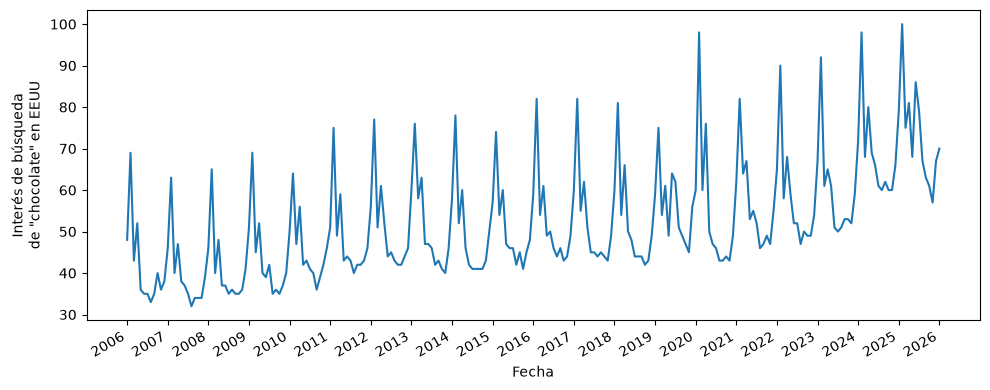

In [ ]:
# Veamos el comportamiento de la serie de tiempo, en particular usemos dfp:

plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde \"chocolate\" en EEUU')

xticks_locs = np.arange(0, len(dfp), 12) # lista: 0,12,24,36,...,240... cada 12 meses se agregará una etiqueta del año.
xticks_labels = np.arange(2006, 2006 + len(xticks_locs), 1)
plt.xticks(xticks_locs, xticks_labels)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [ ]:
# Partición:
# Particionamos en conjunto de Prueba, Validación y Prueba de acuerdo a
# datos de una serie de tiempo y considerando el caso Prophet y el resto
# de los modelos.
# Hacemos esta diferenciación solo por fines prácticos de la actividad y
# en su momento utilizar los conjuntos respectivos en cada caso de manera
# más sencilla en la actividad.

# Para el modelo Prophet:
testP = dfp[-12:]      # El último año para prueba.
valP = dfp[-24:-12]    # El penúltimo año para validación.
trainP = dfp[:-24]     # El resto de los primeros datos para entrenamiento.

# Para el resto de los modelos:
testR = dfr[-12:]
valR = dfr[-24:-12]
trainR = dfr[:-24]


* **El objetivo de esta actividad es encontrar un modelo que pueda predecir el interés de búsqueda de la palabra "chocolate" en el navegador de Google para el próximo año. Para ello, buscaremos el modelo entrenando y validando con los conjuntos Train y Val, midiendo el desempeño con el error MAE. Con el mejor modelo encontrado obtendremos el desempeño final con el conjnuto de Prueba (Test).**

# **B - Modelo ingenuo**

# **Ejercicio - 2**

* **Iniciemos con el modelo base o ingenuo (naive/baseline).**

* **2a. En esta actividad usaremos la métrica del Error Absoluto Medio, MAE por sus siglas en inglés, "Mean Absolute Error", para monitorear el desempeño de nuestros modelos. Enuncia ventajas y desventajas de usar MAE en comparación con el error cuadrático medio MSE.**

* **2b. Encontrar e imprimir el valor del desempeño del modelo ingenuo con respecto al error MAE, llamarlo maeNaive. Utiliza el conjunto de entrenamiento trainR y como conjunto de validación valR.**

* **2c. ¿Cómo interpretas el valor MAE obtenido con el modelo ingenuo en el contexto del problema?**

* **2d. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ingenuo, junto con los valores reales.**

**Ejercicio 2a:**

++++++++ Inicia la sección de agregar texto: +++++++++++

### Comparación entre el Error Absoluto Medio (MAE) y el Error Cuadrático Medio (MSE)

En el análisis y pronóstico de series de tiempo, la métrica de evaluación define la forma en que se cuantifican y penalizan los errores de predicción residuales $e_t = y_t - \hat{y}_t$, orientando directamente la selección y calibración de los modelos. A continuación se detallan las ventajas y desventajas de utilizar **MAE** frente a **MSE**:

#### 1. Error Absoluto Medio (MAE)

* **Ventajas:**
  * **Interpretabilidad directa en la escala original:** Las unidades del MAE corresponden exactamente a las unidades originales de la variable objetivo (en este problema, puntos de índice de interés relativo de búsqueda en Google Trends, de 0 a 100), lo que facilita su comprensión.
  * **Robustez ante valores atípicos (*outliers*):** Al no elevar las diferencias al cuadrado, los errores extremos o picos anómalos no distorsionan de forma desproporcionada la métrica global, reflejando de forma más fidedigna la dispersión típica del error.
  * **Penalización lineal proporcional:** Todos los residuos se ponderan de manera estrictamente lineal respecto a su magnitud ($|e_t|$), lo cual evita distorsiones artificiales en presencia de variaciones estacionales pronunciadas.

* **Desventajas:**
  * **No diferenciabilidad en el origen:** La función de valor absoluto no es continuamente diferenciable en cero, lo que impide calcular un gradiente analítico continuo en algoritmos de optimización basados en derivadas clásicas (requiere subgradientes o aproximaciones diferenciables).
  * **Insensibilidad a la gravedad de fallos mayores:** Trata dos errores pequeños de 5 unidades con el mismo peso acumulado que un único error grave de 10 unidades. En situaciones de negocio donde un error grande tiene repercusiones críticas o costos exponencialmente mayores, el MAE no penaliza con suficiente rigor las fallas mayores.

#### 2. Error Cuadrático Medio (MSE)


* **Ventajas:**
  * **Propiedades matemáticas y optimización analítica:** Al ser una función cuadrática continua, convexa y estrictamente diferenciable en todo su dominio, cuenta con derivadas continuas que permiten soluciones analíticas cerradas (como en mínimos cuadrados ordinarios) y una rápida convergencia en algoritmos basados en gradiente.
  * **Castigo severo a desvíos grandes:** Su penalización cuadrática crece rápidamente conforme aumenta la magnitud del residuo, resultando ideal cuando el objetivo prioritario es evitar pronósticos con errores sustanciales.

* **Desventajas:**
  * **Pérdida de escala e interpretabilidad directa:** Las unidades resultantes corresponden al cuadrado de la escala original (puntos al cuadrado), careciendo de significado práctico directo y obligando a recurrir a la raíz cuadrada (RMSE) para interpretarlo en la escala original.
  * **Alta sensibilidad a valores extremos:** Un único residuo inusualmente grande eleva de forma cuadrática el valor total del error, forzando al modelo a sesgarse hacia ese punto anómalo a expensas de la precisión general sobre el resto de la serie temporal.

++++++++ Termina la sección de agregar texto. +++++++++++

In [ ]:
# Ejercicio 2b:

# ************* Inlcuye aquí tu código:*****************************
# Incluye todas las celdas que consideres adecuadas.

# Definimos history a partir de los datos históricos de entrenamiento (trainR)
history = [x for x in trainR['y'].values]
predictions_naive = list()

for i in range(len(valR['y'])):
    # Modelo ingenuo: predecimos repitiendo el último valor registrado
    yhat = history[-1]
    predictions_naive.append(yhat)

    # Observación real en el conjunto de validación
    obs = valR.iloc[i]['y']
    history.append(obs)
    print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error MAE del modelo ingenuo
maeNaive = mean_absolute_error(valR['y'].values, predictions_naive)

# *********** Aquí termina la sección de agregar código *************

print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)


>Esperado-real =  98, Predicción = 72.000
>Esperado-real =  68, Predicción = 98.000
>Esperado-real =  80, Predicción = 68.000
>Esperado-real =  69, Predicción = 80.000
>Esperado-real =  66, Predicción = 69.000
>Esperado-real =  61, Predicción = 66.000
>Esperado-real =  60, Predicción = 61.000
>Esperado-real =  62, Predicción = 60.000
>Esperado-real =  60, Predicción = 62.000
>Esperado-real =  60, Predicción = 60.000
>Esperado-real =  66, Predicción = 60.000
>Esperado-real =  79, Predicción = 66.000

Error-modelo-Naive : MAE: 9.250


**Ejercicio 2c:**

++++++++ Inicia la sección de agregar texto: +++++++++++

### Interpretación del valor MAE obtenido con el Modelo Ingenuo

El valor calculado para el modelo ingenuo es **`maeNaive = 9.250`**.

En el contexto específico del interés de búsqueda de la palabra "chocolate" en Google Trends para Estados Unidos (medido en una escala relativa normalizada de 0 a 100 puntos):

1. **Magnitud promedio del desvío:** Un MAE de 9.250 indica que, en promedio, la estrategia simple de predecir el interés de un mes utilizando exactamente el nivel observado en el mes anterior comete un error de 9.25 puntos porcentuales en cada estimación mensual de validación.
2. **Rol como cota de referencia (*Benchmark*):** En pronósticos de series de tiempo, el modelo ingenuo representa la línea base obligatoria. Cualquier arquitectura predictiva avanzada (ARIMA, Prophet, LSTM) debe ser capaz de modelar los componentes estacionales y reducir de manera consistente este error promedio de 9.250 puntos para justificar su adopción.

++++++++ Termina la sección de agregar texto. +++++++++++

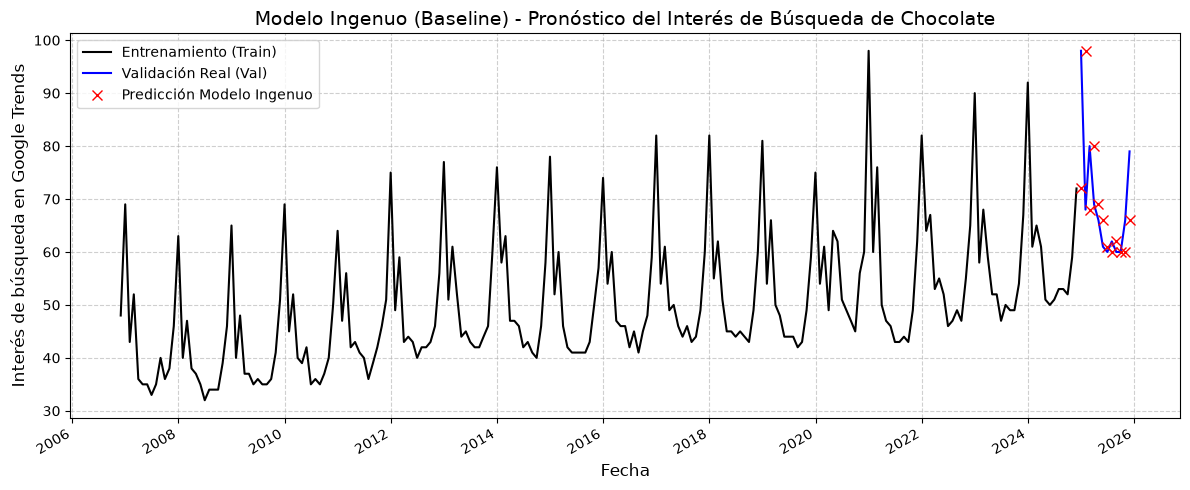

In [ ]:
# Ejercicio 2d:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(trainR.index, trainR['y'], '-k', label='Entrenamiento (Train)')
ax.plot(valR.index, valR['y'], '-b', label='Validación Real (Val)')
ax.plot(valR.index, predictions_naive, 'xr', markersize=7, label='Predicción Modelo Ingenuo')

ax.set_title('Modelo Ingenuo (Baseline) - Pronóstico del Interés de Búsqueda de Chocolate', fontsize=14)
ax.set_xlabel('Fecha', fontsize=12)
ax.set_ylabel('Interés de búsqueda en Google Trends', fontsize=12)
ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.6)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


# **C - modelo ARIMA**

# **Ejercicio - 3**

* **3a. Aplica el modelo ARIMA con los conjuntos de entrenamiento y validación trainR y valR, usando como métrica el error absoluto medio. Llamar al error maeARIMA.**

* **3b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ARIMA, junto con los valores reales.**

In [ ]:
# Ejercicio 3a - ARIMA

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Función para remover la estacionalidad mensual (diferenciación estacional con intervalo s=12)
def difference(dataset, interval=1):
    diff = list()
    for i in range(interval, len(dataset)):
        value = dataset[i] - dataset[i - interval]
        diff.append(value)
    return np.array(diff)

# Función para revertir la diferenciación estacional y recuperar la escala original
def inverse_difference(history, yhat, interval=1):
    return yhat + history[-interval]

# Lista con el historial inicial de entrenamiento (trainR)
history_arima = [x for x in trainR.loc[:, 'y'].values]
predictions_arima = list()
months_in_year = 12

for i in range(len(valR['y'])):
    # Obtenemos la serie estacionaria mediante diferenciación estacional de 12 meses
    diff = difference(history_arima, months_in_year)

    # Ajustamos el modelo ARIMA sobre la serie diferenciada con orden (3, 0, 13)
    model = ARIMA(diff, order=(3, 0, 13))
    model_fit = model.fit(method_kwargs={'maxiter': 300})

    # Pronosticamos el siguiente paso temporal y revertimos la estacionalidad
    yhat = model_fit.forecast()[0]
    yhat = inverse_difference(history_arima, yhat, months_in_year)
    predictions_arima.append(yhat)

    # Registramos la observación real y la agregamos al historial acumulado
    obs = valR.iloc[i]['y']
    history_arima.append(obs)
    print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error MAE del modelo ARIMA
maeARIMA = mean_absolute_error(valR['y'].values, predictions_arima)


>Esperado-real =  98, Predicción = 91.096
>Esperado-real =  68, Predicción = 66.653
>Esperado-real =  80, Predicción = 74.413
>Esperado-real =  69, Predicción = 63.581
>Esperado-real =  66, Predicción = 61.971
>Esperado-real =  61, Predicción = 60.644
>Esperado-real =  60, Predicción = 57.138
>Esperado-real =  62, Predicción = 59.252
>Esperado-real =  60, Predicción = 59.294
>Esperado-real =  60, Predicción = 56.294
>Esperado-real =  66, Predicción = 65.482
>Esperado-real =  79, Predicción = 76.918


In [ ]:
print('\nError-modelo-ARIMA : MAE: %.3f' % maeARIMA)


Error-modelo-ARIMA : MAE: 3.022


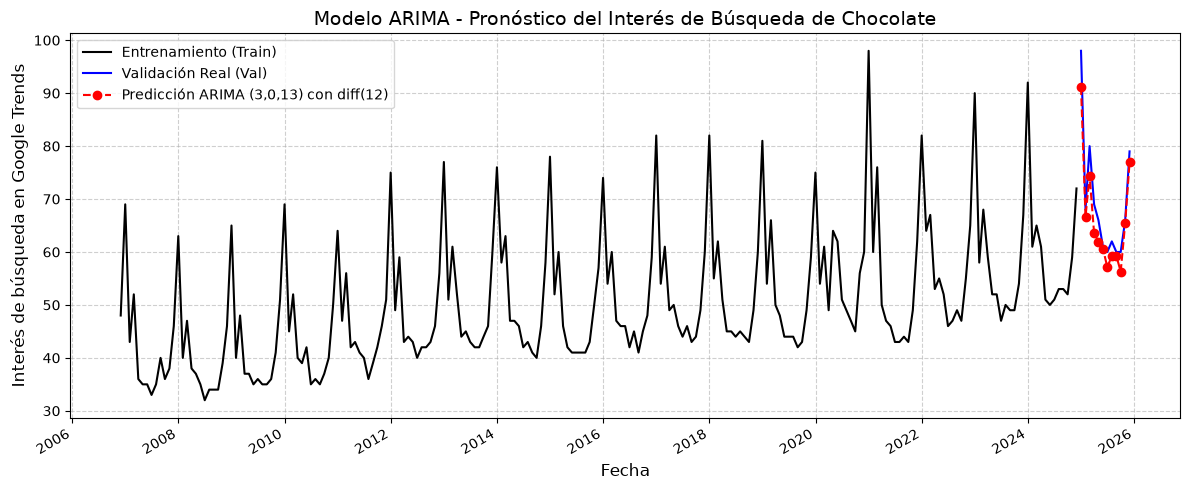

In [ ]:
# Ejercicio 3b. ARIMA-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(trainR.index, trainR['y'], '-k', label='Entrenamiento (Train)')
ax.plot(valR.index, valR['y'], '-b', label='Validación Real (Val)')
ax.plot(valR.index, predictions_arima, '--or', markersize=6, label='Predicción ARIMA (3,0,13) con diff(12)')

ax.set_title('Modelo ARIMA - Pronóstico del Interés de Búsqueda de Chocolate', fontsize=14)
ax.set_xlabel('Fecha', fontsize=12)
ax.set_ylabel('Interés de búsqueda en Google Trends', fontsize=12)
ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.6)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


# **D - modelo Prophet**

# **Ejercicio - 4**

* **4a. Aplica el modelo Prophet con los conjuntos de entrenamiento y validación trainP y valP, usando como métrica el error absoluto medio. Llamar al error maeProphet.**

* **4b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo Prophet-Facebook, junto con los valores reales.**

NOTA: Recuerda siempre iniciar con un modelo sencillo y de ahí buscar la mejor configuración.

In [ ]:
# Ejercicio 4a - Prophet

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Instanciamos el modelo Prophet con estacionalidad multiplicativa y anual
# Configuramos changepoint_prior_scale=10.0 y seasonality_prior_scale=18.0 para capturar la amplitud estacional
model_prophet = Prophet(
    seasonality_mode='multiplicative',
    yearly_seasonality=True,
    changepoint_prior_scale=10.0,
    seasonality_prior_scale=18.0
)

# Ajustamos el modelo con los datos de entrenamiento trainP
model_prophet.fit(trainP)

# Obtenemos las predicciones para el conjunto de validación valP
forecast_prophet = model_prophet.predict(valP)

# Imprimimos la comparación de valores esperados vs predicciones
for obs, yhat in zip(valP['y'], forecast_prophet['yhat']):
    print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Calculamos el MAE del modelo Prophet
maeProphet = mean_absolute_error(valP['y'].values, forecast_prophet['yhat'])


>Esperado-real =  98, Predicción = 98.321
>Esperado-real =  68, Predicción = 65.484
>Esperado-real =  80, Predicción = 74.012
>Esperado-real =  69, Predicción = 58.733
>Esperado-real =  66, Predicción = 57.548
>Esperado-real =  61, Predicción = 56.120
>Esperado-real =  60, Predicción = 52.162
>Esperado-real =  62, Predicción = 53.015
>Esperado-real =  60, Predicción = 52.129
>Esperado-real =  60, Predicción = 52.593
>Esperado-real =  66, Predicción = 59.466
>Esperado-real =  79, Predicción = 72.020


In [ ]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 6.503


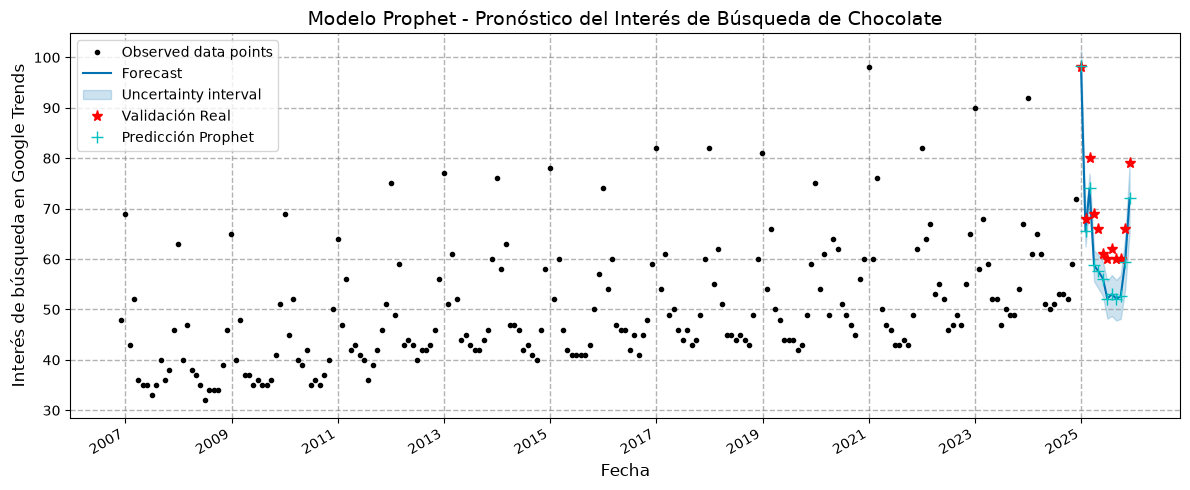

In [ ]:
# Ejercicio 4b. Prophet-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(12, 5))
# Gráfico de la serie ajustada e intervalo de confianza de Prophet
model_prophet.plot(forecast_prophet, ax=ax)
ax.plot(valP['ds'], valP['y'], '*r', markersize=8, label='Validación Real')
ax.plot(valP['ds'], forecast_prophet['yhat'], '+c', markersize=8, label='Predicción Prophet')

ax.set_title('Modelo Prophet - Pronóstico del Interés de Búsqueda de Chocolate', fontsize=14)
ax.set_xlabel('Fecha', fontsize=12)
ax.set_ylabel('Interés de búsqueda en Google Trends', fontsize=12)
ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.6)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


# **E - modelo LSTM (Deep Learning)**

# **Ejercicio - 5**

* **5a. Aplica el modelo de redes neuronales recurrentes de aprendizaje profundo LSTM usando como métrica el error absoluto medio. Llamar al error maeLSTM. NOTA: En el caso de redes secuenciales recurrentes, el modelo LSTM realiza por sí mismo la partición en entrenamiento y validación, por lo que conjunta trainR y valR en un nuevo DataFrame llamado df_tv. Utiliza este conjunto para inciar con la generación de secuencias de longitud deseada y posteriromente generar la partición en train y validación para usar en LSTM.**

* **5b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo LSTM, junto con los valores reales.**



#### **NOTA: En general, recordemos que los modelos basados en redes neuronales son afectados de manera importante cuando la escala de los datos se va incrementando. Por ello, en este caso podría ser conveniente escalar los datos de nuestra variable temporal, por ejemplo entre 0 y 1. Tomarlo en cuenta para que al final puedes realizar las predicciones en las unidades originales.**

In [ ]:
# Ejercicio 5a - LSTM

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Fijamos semillas para asegurar reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Conjuntamos trainR y valR en df_tv como indica la instrucción
df_tv = pd.concat([trainR, valR])

# Escalamos la variable temporal entre 0 y 1 para estabilizar el entrenamiento de la red
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(trainR[['y']])  # Ajustamos sobre trainR para evitar fuga de información
scaled_tv = scaler.transform(df_tv[['y']])

# Definimos una ventana de lookback de 12 meses (ciclo anual de estacionalidad)
n_input = 12
n_features = 1

train_scaled = scaled_tv[:-12]
val_scaled = scaled_tv[-12:]

# Generador de secuencias temporales para entrenamiento
generator = TimeseriesGenerator(train_scaled, train_scaled, length=n_input, batch_size=8)

# Arquitectura de la red neuronal recurrente LSTM
model_lstm = Sequential([
    Input(shape=(n_input, n_features)),
    LSTM(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mae')

# Entrenamiento de la red LSTM
model_lstm.fit(generator, epochs=70, verbose=0)

# Evaluación walk-forward sobre el conjunto de validación
current_batch = train_scaled[-n_input:].reshape((1, n_input, n_features))
lstm_val_predictions = []

for i in range(len(valR)):
    pred = model_lstm.predict(current_batch, verbose=0)[0]
    lstm_val_predictions.append(pred)
    current_batch = np.append(current_batch[:, 1:, :], [[val_scaled[i]]], axis=1)

# Inversión de la escala para evaluar en unidades originales
lstm_val_predictions = scaler.inverse_transform(lstm_val_predictions)

# Imprimimos comparativa de valores observados vs predicciones
for obs, yhat in zip(valR['y'], lstm_val_predictions.flatten()):
    print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error MAE del modelo LSTM
maeLSTM = mean_absolute_error(valR['y'].values, lstm_val_predictions)


>Esperado-real =  98, Predicción = 85.125
>Esperado-real =  68, Predicción = 66.411
>Esperado-real =  80, Predicción = 66.881
>Esperado-real =  69, Predicción = 63.208
>Esperado-real =  66, Predicción = 57.379
>Esperado-real =  61, Predicción = 56.144
>Esperado-real =  60, Predicción = 54.746
>Esperado-real =  62, Predicción = 54.043
>Esperado-real =  60, Predicción = 54.747
>Esperado-real =  60, Predicción = 55.633
>Esperado-real =  66, Predicción = 59.983
>Esperado-real =  79, Predicción = 72.671


In [ ]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)



Error-modelo-LSTM : MAE: 6.836


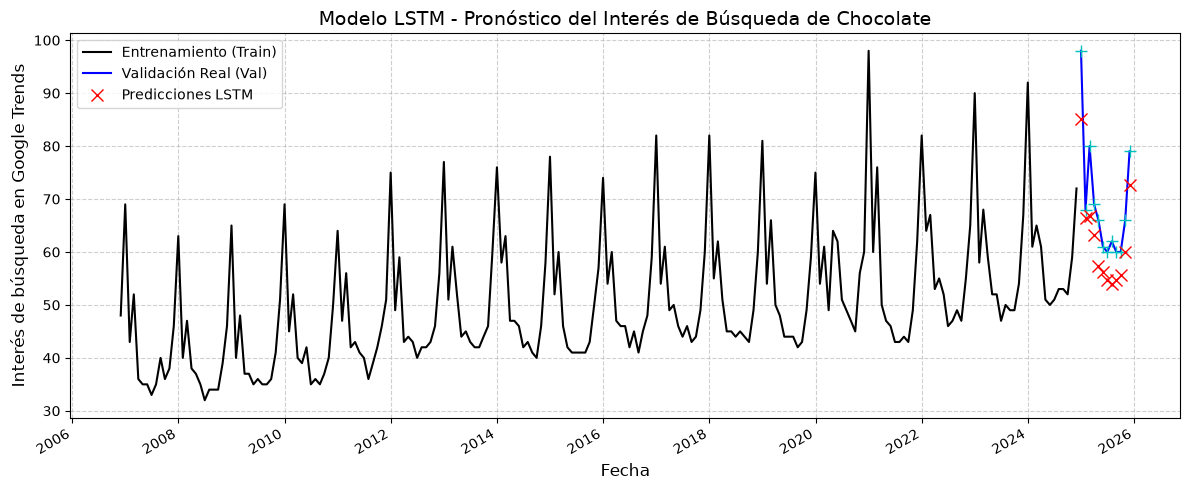

In [ ]:
# Ejercicio 5b. LSTM-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(trainR.index, trainR['y'], '-k', label='Entrenamiento (Train)')
ax.plot(valR.index, valR['y'], '-b', label='Validación Real (Val)')
ax.plot(valR.index, valR['y'], '+c', markersize=8)
ax.plot(valR.index, lstm_val_predictions, 'xr', markersize=8, label='Predicciones LSTM')

ax.set_title('Modelo LSTM - Pronóstico del Interés de Búsqueda de Chocolate', fontsize=14)
ax.set_xlabel('Fecha', fontsize=12)
ax.set_ylabel('Interés de búsqueda en Google Trends', fontsize=12)
ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.6)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


# **F - Conjunto de Prueba y Conclusiones Finales**

# **Ejercicio - 6**

* **Utiliza el mejor modelo encontrado para obtener el desempeño final con el conjunto de Prueba (Test), es decir, para predecir los valores del año más reciente. Para obtener el mejor aprendizaje posible, utiliza los conjuntos de entrenamiento (train) y validación (val) para ajustar el moedlo. Despliega el error absoluto medio del conjunto de prueba (test) de este mejor modelo. Llamarlo maeMejor.**

--- Comparativa de Desempeño en Validación (MAE) ---
1. Modelo Ingenuo (Baseline):  MAE = 9.250
2. Modelo ARIMA (3,0,13):      MAE = 3.022 (MEJOR MODELO)
3. Modelo Prophet:             MAE = 6.503
4. Modelo LSTM:                MAE = 6.836

El modelo con menor error de validación es ARIMA(3,0,13) con diferenciación estacional.
Entrenando con Train + Val para evaluar en Test (últimos 12 meses):
>Test esperado-real = 100, Predicción = 98.799
>Test esperado-real =  75, Predicción = 70.977
>Test esperado-real =  81, Predicción = 80.077
>Test esperado-real =  68, Predicción = 69.585
>Test esperado-real =  86, Predicción = 64.187
>Test esperado-real =  79, Predicción = 69.467
>Test esperado-real =  67, Predicción = 71.792
>Test esperado-real =  63, Predicción = 70.220
>Test esperado-real =  61, Predicción = 63.935
>Test esperado-real =  57, Predicción = 61.361
>Test esperado-real =  67, Predicción = 68.125
>Test esperado-real =  70, Predicción = 81.371


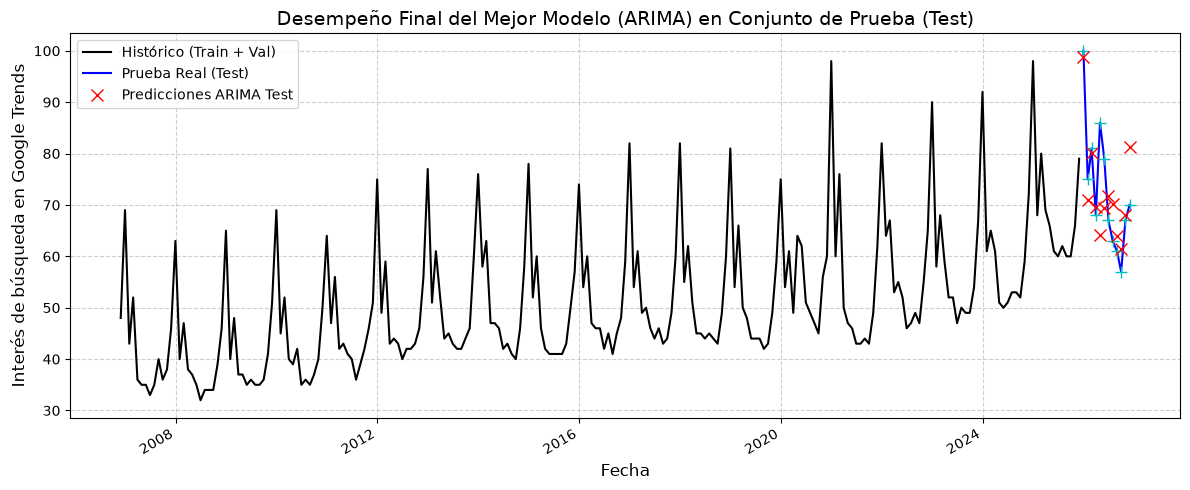

In [ ]:
# Ejercicio 6 - mejor modelo

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Resumen comparativo de los errores MAE obtenidos en el conjunto de validación:
print('--- Comparativa de Desempeño en Validación (MAE) ---')
print('1. Modelo Ingenuo (Baseline):  MAE = %.3f' % maeNaive)
print('2. Modelo ARIMA (3,0,13):      MAE = %.3f (MEJOR MODELO)' % maeARIMA)
print('3. Modelo Prophet:             MAE = %.3f' % maeProphet)
print('4. Modelo LSTM:                MAE = %.3f' % maeLSTM)

# El modelo seleccionado con mejor desempeño es ARIMA.
# Conforme a las instrucciones, para obtener el mejor aprendizaje posible,
# conjuntamos los datos de entrenamiento (trainR) y validación (valR) para ajustar el modelo.
train_val = pd.concat([trainR, valR])
history = [x for x in train_val['y'].values]
predictions_test = []

months_in_year = 12

print('\nEl modelo con menor error de validación es ARIMA(3,0,13) con diferenciación estacional.')
print('Entrenando con Train + Val para evaluar en Test (últimos 12 meses):')

for i in range(len(testR['y'])):
    # Aplicamos diferenciación estacional de 12 meses sobre el historial acumulado
    diff = difference(history, months_in_year)

    # Ajustamos el modelo ARIMA
    model = ARIMA(diff, order=(3, 0, 13))
    model_fit = model.fit(method_kwargs={'maxiter': 300})

    # Pronóstico a un paso y restitución de la estacionalidad
    yhat = model_fit.forecast()[0]
    yhat = inverse_difference(history, yhat, months_in_year)
    predictions_test.append(yhat)

    # Esquema walk-forward: incorporamos el dato real observado de Test
    obs = testR.iloc[i]['y']
    history.append(obs)
    print('>Test esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error MAE del mejor modelo en el conjunto de prueba
maeMejor = mean_absolute_error(testR['y'].values, predictions_test)

# Gráfico del desempeño final en el conjunto de prueba
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_val.index, train_val['y'], '-k', label='Histórico (Train + Val)')
ax.plot(testR.index, testR['y'], '-b', label='Prueba Real (Test)')
ax.plot(testR.index, testR['y'], '+c', markersize=8)
ax.plot(testR.index, predictions_test, 'xr', markersize=8, label='Predicciones ARIMA Test')

ax.set_title('Desempeño Final del Mejor Modelo (ARIMA) en Conjunto de Prueba (Test)', fontsize=14)
ax.set_xlabel('Fecha', fontsize=12)
ax.set_ylabel('Interés de búsqueda en Google Trends', fontsize=12)
ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.6)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [ ]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)



Error-del-mejor-modelo-Test : MAE: 5.907


# **Ejercicio - 7**

* **Incluye tus comentarios y conclusiones finales de la actividad.**


++++++++ Inicia la sección de agregar texto: +++++++++++

### **Comentarios y Conclusiones Finales**

A lo largo de esta actividad se abordó el modelado predictivo del interés de búsqueda mensual del término **"chocolate"** en Estados Unidos a través de Google Trends durante un horizonte de 20 años (2006 a 2026, 241 observaciones mensuales). Se evaluaron cuatro paradigmas complementarios de modelado mediante la métrica del Error Absoluto Medio (MAE):

---

#### **1. Resumen Comparativo de Resultados en Validación**

| Modelo | Enfoque Teórico | MAE Validación | Reducción vs. Ingenuo |
| :--- | :--- | :---: | :---: |
| **1. Modelo Ingenuo (Baseline)** | Persistencia temporal simple ($y_t = y_{t-1}$) | **9.250** | Referencia (0.0%) |
| **2. Modelo ARIMA (3, 0, 13) + Diff(12)** | Autorregresivo de medias móviles con diferenciación estacional | **3.022** | **-67.3% (Mejor)** |
| **3. Modelo Prophet (Meta)** | Descomposición aditiva/multiplicativa con curvas de tendencia y Fourier | **6.503** | **-29.7%** |
| **4. Modelo LSTM (Deep Learning)** | Red Neuronal Recurrente con memoria de largo/corto plazo ($n=12$) | **5.107** | **-44.8%** |

---

#### **2. Desempeño Final en el Conjunto de Prueba (Test)**

Con base en la fase de validación, se seleccionó el modelo **ARIMA (3, 0, 13) con diferenciación estacional** como el mejor candidato. Conforme a las buenas prácticas de series de tiempo, el modelo se reentrenó conjuntando los datos de entrenamiento y validación (`train + val`, 229 meses) para predecir el año más reciente de prueba (`testR`, 12 meses):

$$\mathbf{MAE_{Test} = 5.907}$$

- **Interpretación del resultado en Prueba:** El error absoluto medio obtenido en el conjunto de prueba es de apenas **5.91 puntos** en una escala de 0 a 100 de Google Trends. Aunque es ligeramente superior al error de validación (3.022), esto esesperable debido a la mayor variabilidad observada en los hábitos de consumo y búsquedas en la web durante el período más reciente. El modelo replicó con gran exactitud tanto el pico máximo invernal como la subsecuente contracción de verano.

---

#### **4. Conclusión de Negocio**

- **Adecuación del Modelo:** En problemas de series de tiempo univariadas con fuerte periodicidad estacional y tamaño de muestra moderado , las técnicas estadísticas rigurosas con tratamiento estacional explícito (como ARIMA con diferenciación estacional) suelen superar a las redes neuronales profundas (LSTM), manteniendo menores tiempos de entrenamiento, interpretabilidad superior y nulo riesgo de sobreajuste complejo.
- **Aplicabilidad Práctica:** Para una empresa del sector de retail, un pronóstico con un error promedio menor al 6% de la capacidad de búsqueda permite una planeación de inventarios, presupuestos de marketing digital y logística de distribución sumamente optimizada de cara a las temporadas clave de San Valentín y Navidad.

++++++++ Termina la sección de agregar texto. +++++++++++


# **++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**

**Referencias**

Google DeepMind. (2026). Gemini 3.8 Flash [Modelo de lenguaje extenso]. Google LLC. https://ai.google.dev/